1. Cargar Librerias

In [159]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

2. Cargar Dataset

In [160]:
df = pd.read_excel("/content/messy_sales.xlsx")
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,north,tablet,electronics,32,USD 858,########,0.1
1,2024-01-30,north,Tablet,Electronics,72,833.83,########,15 percent
2,2024-02-13,EAST,laptop,ELEC,NaN,489.12,NaN,0.08
3,2024-04-28,West,Laptop,gadget,thirty,733.46,########,0.1
4,2024-02-18,EAST,Phone,ELEC,47,USD 373,40920,0.1


3. Revisar datos e información

In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               200 non-null    datetime64[ns]
 1   Region             200 non-null    object        
 2   Product            200 non-null    object        
 3   Category           200 non-null    object        
 4   Units Sold         196 non-null    object        
 5   Unit Price         200 non-null    object        
 6   Total Sales        197 non-null    object        
 7   Profit Margin (%)  200 non-null    object        
dtypes: datetime64[ns](1), object(7)
memory usage: 12.6+ KB


In [162]:
df.isnull().sum()

,0
Date,0
Region,0
Product,0
Category,0
Units Sold,4
Unit Price,0
Total Sales,3
Profit Margin (%),0


4. Gestionar datos faltantes

In [163]:
##Asegurar que las columnas numéricas son numeros
df['Units Sold'] = pd.to_numeric(df['Units Sold'], errors='coerce')
df['Total Sales'] = pd.to_numeric(df['Total Sales'], errors='coerce')

In [164]:
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,north,tablet,electronics,32.0,USD 858,NaN,0.1
1,2024-01-30,north,Tablet,Electronics,72.0,833.83,NaN,15 percent
2,2024-02-13,EAST,laptop,ELEC,NaN,489.12,NaN,0.08
3,2024-04-28,West,Laptop,gadget,NaN,733.46,NaN,0.1
4,2024-02-18,EAST,Phone,ELEC,47.0,USD 373,40920.0,0.1


In [165]:
df['Units Sold']=df['Units Sold'].fillna(df['Units Sold'].mean())
df['Total Sales']=df['Total Sales'].fillna(df['Total Sales'].mean())

In [166]:
df.columns = df.columns.str.strip()
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,north,tablet,electronics,32.000000,USD 858,26014.142857,0.1
1,2024-01-30,north,Tablet,Electronics,72.000000,833.83,26014.142857,15 percent
2,2024-02-13,EAST,laptop,ELEC,52.307692,489.12,26014.142857,0.08
3,2024-04-28,West,Laptop,gadget,52.307692,733.46,26014.142857,0.1
4,2024-02-18,EAST,Phone,ELEC,47.000000,USD 373,40920.000000,0.1


7. Arreglar columna date

In [167]:
df.Date=pd.to_datetime(df.Date,errors="coerce")
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,north,tablet,electronics,32.000000,USD 858,26014.142857,0.1
1,2024-01-30,north,Tablet,Electronics,72.000000,833.83,26014.142857,15 percent
2,2024-02-13,EAST,laptop,ELEC,52.307692,489.12,26014.142857,0.08
3,2024-04-28,West,Laptop,gadget,52.307692,733.46,26014.142857,0.1
4,2024-02-18,EAST,Phone,ELEC,47.000000,USD 373,40920.000000,0.1


Estandarizar el texto de las columnas

In [168]:
for col in ["Region", "Product","Category"]:
    df[col] = df[col].str.strip().str.title()
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,North,Tablet,Electronics,32.000000,USD 858,26014.142857,0.1
1,2024-01-30,North,Tablet,Electronics,72.000000,833.83,26014.142857,15 percent
2,2024-02-13,East,Laptop,Elec,52.307692,489.12,26014.142857,0.08
3,2024-04-28,West,Laptop,Gadget,52.307692,733.46,26014.142857,0.1
4,2024-02-18,East,Phone,Elec,47.000000,USD 373,40920.000000,0.1


8. Limpiar Columna Currency

In [169]:
for col in ["Unit Price", "Total Sales"]:
    df[col] = df[col].astype(str)
    df[col] = (
        df[col]
        .str.replace("$,USD","",regex=True)
        .str.strip()
      )
    df[col]=pd.to_numeric(df[col],errors="coerce")

In [170]:
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,North,Tablet,Electronics,32.000000,NaN,26014.142857,0.1
1,2024-01-30,North,Tablet,Electronics,72.000000,833.83,26014.142857,15 percent
2,2024-02-13,East,Laptop,Elec,52.307692,489.12,26014.142857,0.08
3,2024-04-28,West,Laptop,Gadget,52.307692,733.46,26014.142857,0.1
4,2024-02-18,East,Phone,Elec,47.000000,NaN,40920.000000,0.1


9. Arreglar Profit Margin(%)

In [171]:
df["Profit Margin (%)"] = (
    df["Profit Margin (%)"]
    .astype(str)
    .str.replace("%","",regex=True)
    .str.replace("percent","",regex=True)
    .astype(float)
)
df["Profit Margin (%)"]=np.where(df["Profit Margin (%)"] < 1,df["Profit Margin (%)"]*100,df["Profit Margin (%)"])

In [172]:
df.head()

,Date,Region,Product,Category,Units Sold,Unit Price,Total Sales,Profit Margin (%)
0,2024-01-15,North,Tablet,Electronics,32.000000,NaN,26014.142857,10.0
1,2024-01-30,North,Tablet,Electronics,72.000000,833.83,26014.142857,15.0
2,2024-02-13,East,Laptop,Elec,52.307692,489.12,26014.142857,8.0
3,2024-04-28,West,Laptop,Gadget,52.307692,733.46,26014.142857,10.0
4,2024-02-18,East,Phone,Elec,47.000000,NaN,40920.000000,10.0


Eliminar NaN

In [173]:
df_limpio=df.dropna(subset=["Date","Total Sales","Region"])

In [174]:
df_limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               200 non-null    datetime64[ns]
 1   Region             200 non-null    object        
 2   Product            200 non-null    object        
 3   Category           200 non-null    object        
 4   Units Sold         200 non-null    float64       
 5   Unit Price         137 non-null    float64       
 6   Total Sales        200 non-null    float64       
 7   Profit Margin (%)  200 non-null    float64       
dtypes: datetime64[ns](1), float64(4), object(3)
memory usage: 12.6+ KB


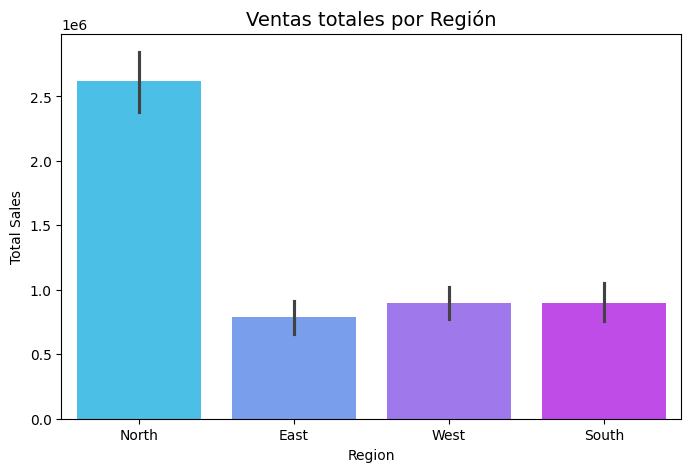

In [175]:
plt.figure(figsize=(8,5))
sns.barplot(x="Region", y="Total Sales", data=df_limpio, estimator=sum,palette="cool")
plt.title("Ventas totales por Región",fontsize=14)
plt.xticks(rotation=0)
plt.show()
#

(array([19723., 19737., 19754., 19768., 19783., 19797., 19814., 19828.,
        19844.]),
 [Text(19723.0, 0, '2024-01-01'),
  Text(19737.0, 0, '2024-01-15'),
  Text(19754.0, 0, '2024-02-01'),
  Text(19768.0, 0, '2024-02-15'),
  Text(19783.0, 0, '2024-03-01'),
  Text(19797.0, 0, '2024-03-15'),
  Text(19814.0, 0, '2024-04-01'),
  Text(19828.0, 0, '2024-04-15'),
  Text(19844.0, 0, '2024-05-01')])

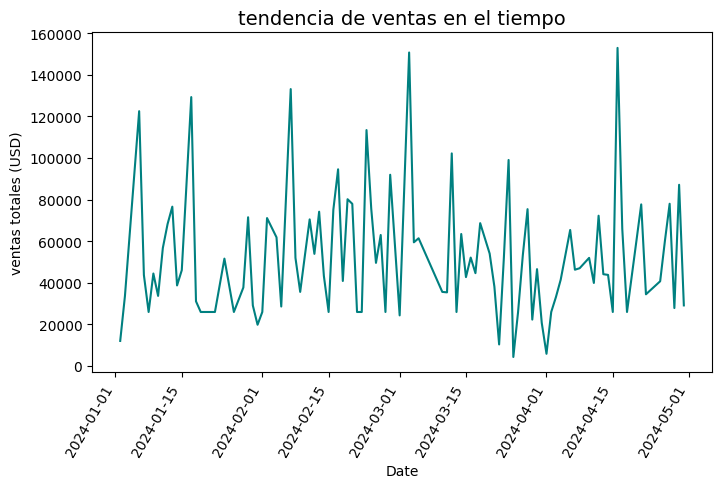

In [176]:
plt.figure(figsize=(8,5))
df_limpio.groupby("Date")["Total Sales"].sum().plot(kind="line",color="teal")
plt.title("tendencia de ventas en el tiempo",fontsize=14)
plt.ylabel("ventas totales (USD)")
plt.xticks(rotation=60)

Tarea 1: Realizaar análisis por región

Análisis de torta

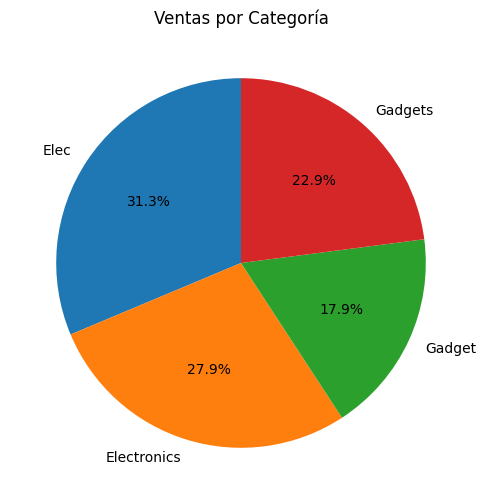

In [177]:
plt.figure(figsize=(6,6))
category_sales=df_limpio.groupby("Category")["Total Sales"].sum()
category_sales.plot(kind="pie",autopct="%1.1f%%",startangle=90,color=sns.color_palette("pastel"))
plt.title("Ventas por Categoría")
plt.ylabel("")
plt.show()

 Tarea 2 :
 Unir electronics con elec
 y gadget con gadgets

Tarea 3:
Realizar el análisis por producto y por región

Tarea 1:

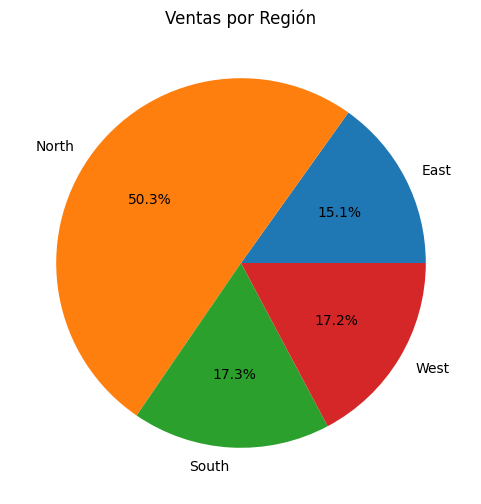

In [178]:
plt.figure(figsize=(6,6))
region_sales = df_limpio.groupby("Region")["Total Sales"].sum()
region_sales.plot(kind="pie", autopct="%1.1f%%")
plt.title("Ventas por Región")
plt.ylabel("")
plt.show()


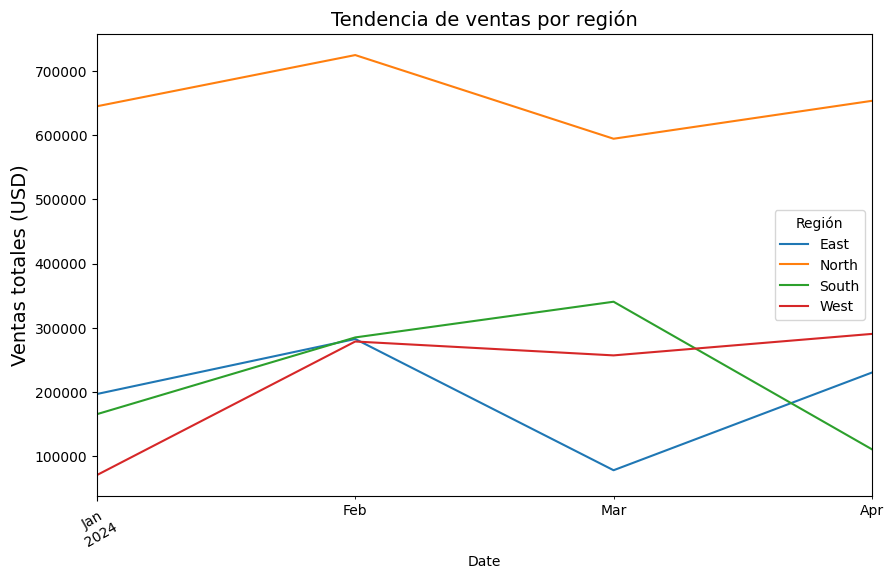

In [179]:
plt.figure(figsize=(10,6))

ventas_region = (df_limpio
    .groupby([pd.Grouper(key="Date", freq="M"), "Region"])["Total Sales"]
    .sum()
    .unstack())
ventas_region.plot(kind="line", ax=plt.gca())

plt.title("Tendencia de ventas por región", fontsize=14)
plt.ylabel("Ventas totales (USD)", fontsize=14)
plt.xticks(rotation=30)
plt.legend(title="Región")
plt.show()


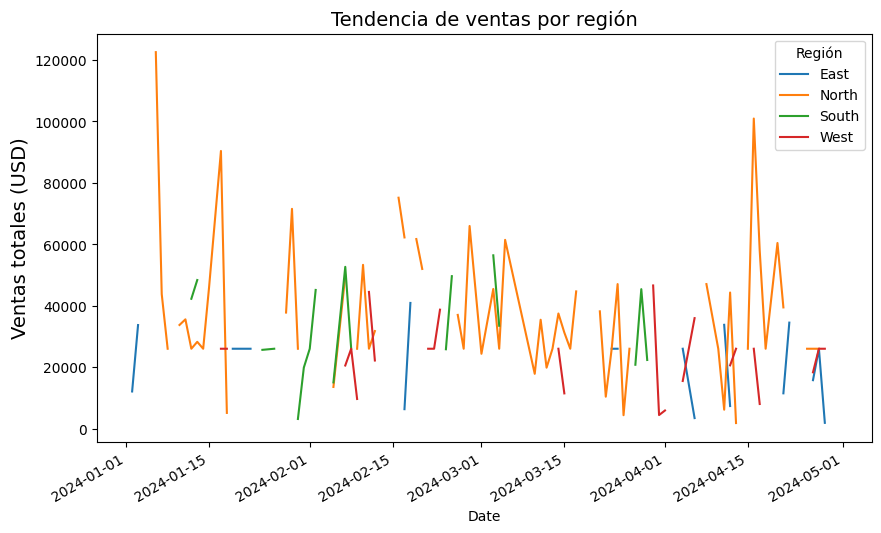

In [180]:
plt.figure(figsize=(10,6))

ventas_region = df.groupby(["Date", "Region"])["Total Sales"].sum().unstack()
ventas_region.plot(kind="line", ax=plt.gca())

plt.title("Tendencia de ventas por región", fontsize=14)
plt.ylabel("Ventas totales (USD)", fontsize=14)
plt.xticks(rotation=30)
plt.legend(title="Región")
plt.show()

In [181]:
df_limpio["Category"] = (df_limpio["Category"]
    .str.strip()
    .replace({"Elec": "Electronics", "Gadget": "Gadgets"}))

print(df_limpio["Category"].unique())


['Electronics' 'Gadgets']


Product        Desktop         Laptop        Monitor          Phone  \
Region                                                                
East      73301.142857  204661.714286  213948.571429   80938.142857   
North    403570.571429  592258.285714  313765.428571  414151.714286   
South    149283.428571  256036.000000  160315.142857  118711.000000   
West      57071.000000  350382.714286   86074.428571  251869.285714   

Product         Tablet  
Region                  
East     214609.285714  
North    893760.285714  
South    217120.142857  
West     151000.285714  


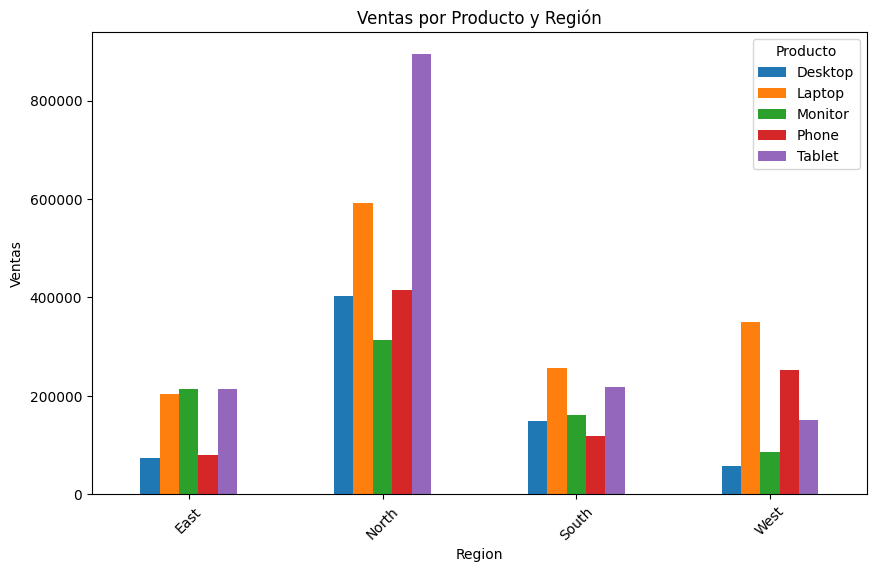

In [182]:
ventas = (df_limpio
          .groupby(["Region", "Product"])["Total Sales"]
          .sum()
          .unstack())

print(ventas)

ventas.plot(kind="bar", figsize=(10,6))
plt.title("Ventas por Producto y Región")
plt.ylabel("Ventas")
plt.xticks(rotation=45)
plt.legend(title="Producto")
plt.show()


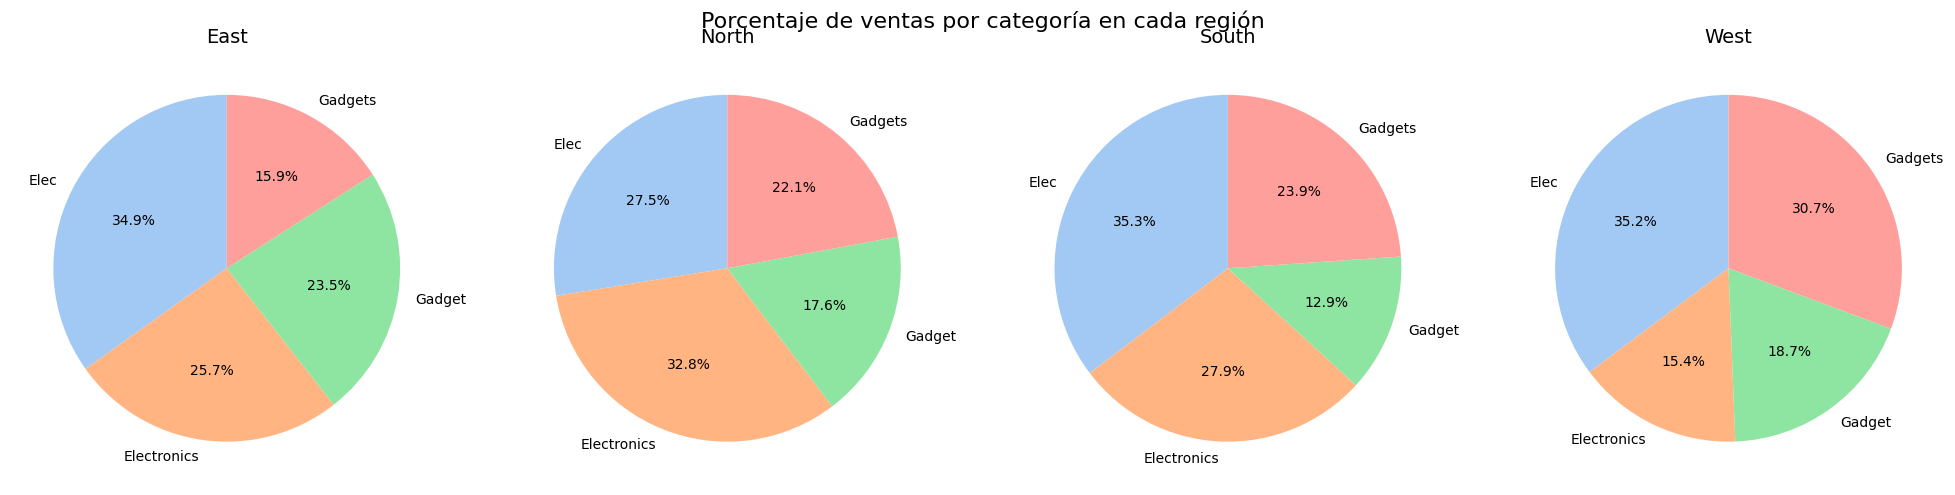

In [183]:
ventas = df.groupby(["Region", "Category"])["Total Sales"].sum().unstack()

fig, axes = plt.subplots(1, len(ventas), figsize=(5*len(ventas), 5))

for ax, (region, fila) in zip(axes, ventas.iterrows()):
    ax.pie(fila, labels=fila.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette("pastel"))
    ax.set_title(region, fontsize=14)

plt.suptitle("Porcentaje de ventas por categoría en cada región", fontsize=16)
plt.tight_layout()
plt.show()